### Zadania

Celem listy jest zbadanie działania metod binaryzacji obrazów w skali szarości i kolorowych. Dążymy do wyobrębnienia obiektów znajdujących się na podanych obrazach, tzn. uzyskania separacji obiektów od tła, a także oddzielenia poszczególnych obiektów. Natomiast samo osiągnięcie "jakiegoś" wyniku ([`cv2.threshold`](https://docs.opencv.org/3.4/d7/d1b/group__imgproc__misc.html#gae8a4a146d1ca78c626a53577199e9c57) odpalone, próg wybrany "z palca", _coś tam_ wychodzi, wynik wyświetlony) to co najwyżej połowa sukcesu i oceny. Ważne jest przeprowadzenie eksperymentów wyjaśniających dobór parametrów.

In [48]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import binary_fill_holes

##### Zad. 1: Monety szare

Dane są dwa czarno-białe obrazy monet, `monety_szare` oraz `monety_szare_szum`, z których drugi zawiera pewien poziom zakłóceń. Dokonaj binaryzacji tych obrazów za pomocą progowania.  
Jak wartość progu wpływa na wyniki?  
Jaki wpływ mają zakłócenia w drugim obrazie? Zastosuj wybraną metodę odszumiania i przeanalizuj efekty.

In [2]:
monety_szare = cv2.imread('Monety_szare.bmp')
monety_szum = cv2.imread('Monety_szare_szum.bmp')

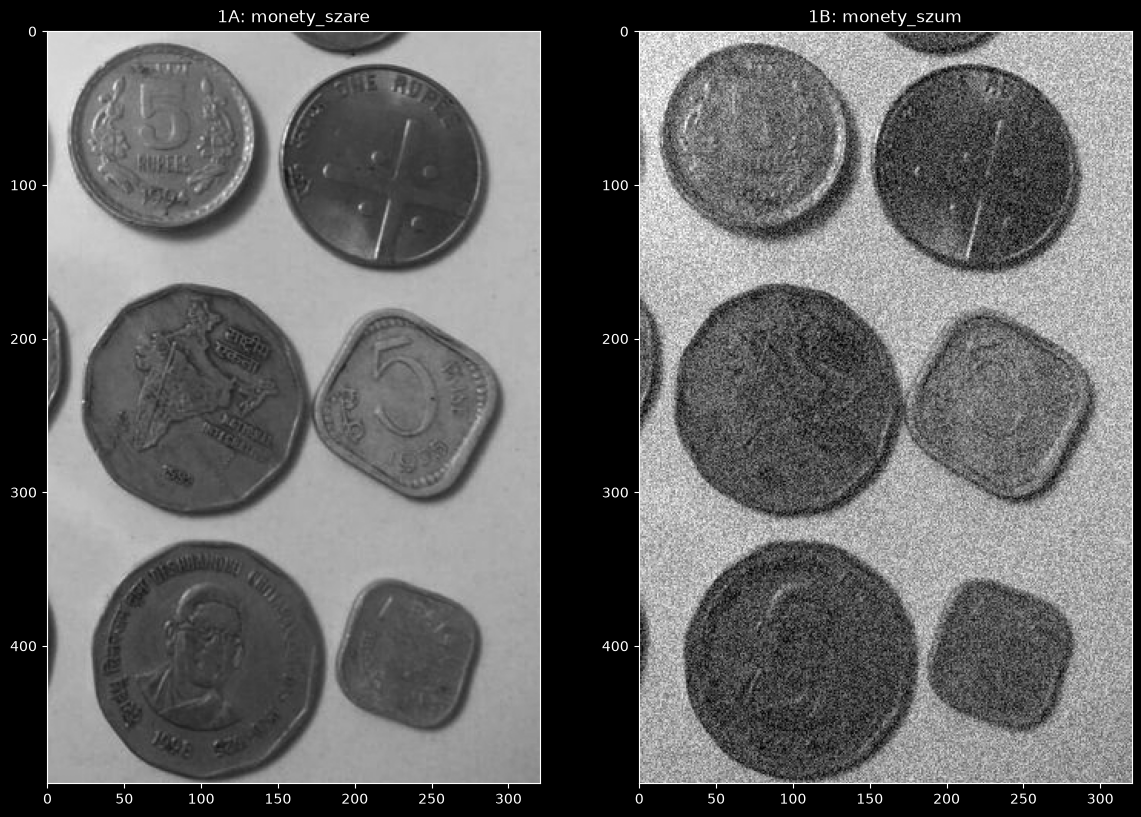

In [3]:
_, (a, b) = plt.subplots(1,2, figsize=(14,10))
a.imshow(monety_szare); a.title.set_text('1A: monety_szare')
b.imshow(monety_szum); b.title.set_text('1B: monety_szum')

Rozwiązanie części 1A:

In [25]:
print("Rozmiar monety_szare: " + monety_szare.shape.__str__())
gray_monety_szare = cv2.cvtColor(monety_szare, cv2.COLOR_BGR2GRAY)

Rozmiar monety_szare: (490, 321, 3)


Rozmiar monety_szare: (490, 321)


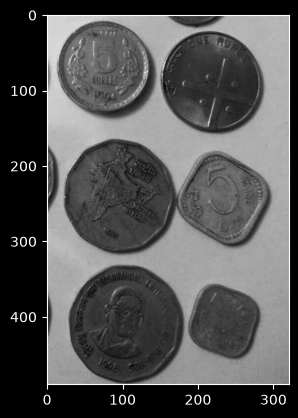

In [28]:
plt.imshow(gray_monety_szare, cmap='gray')
a.title.set_text('1A: gray_monety_szare')

print("Rozmiar monety_szare: " + gray_monety_szare.shape.__str__())

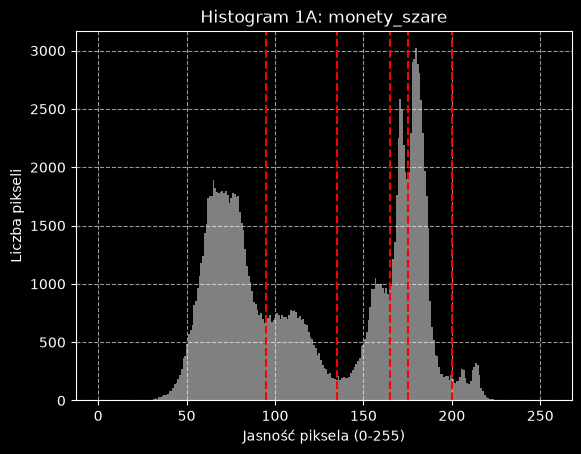

In [31]:
plt.hist(gray_monety_szare.flatten(), bins=256, color='gray', range=(0, 255))

plt.title('Histogram 1A: monety_szare')
plt.xlabel('Jasność piksela (0-255)')
plt.ylabel('Liczba pikseli')
plt.grid(True, linestyle='--', alpha=0.6)

progi = [95, 135, 165, 175, 200]
for p in progi:
    plt.axvline(x=p, color='red', linestyle='--', linewidth=1.5)

plt.show()

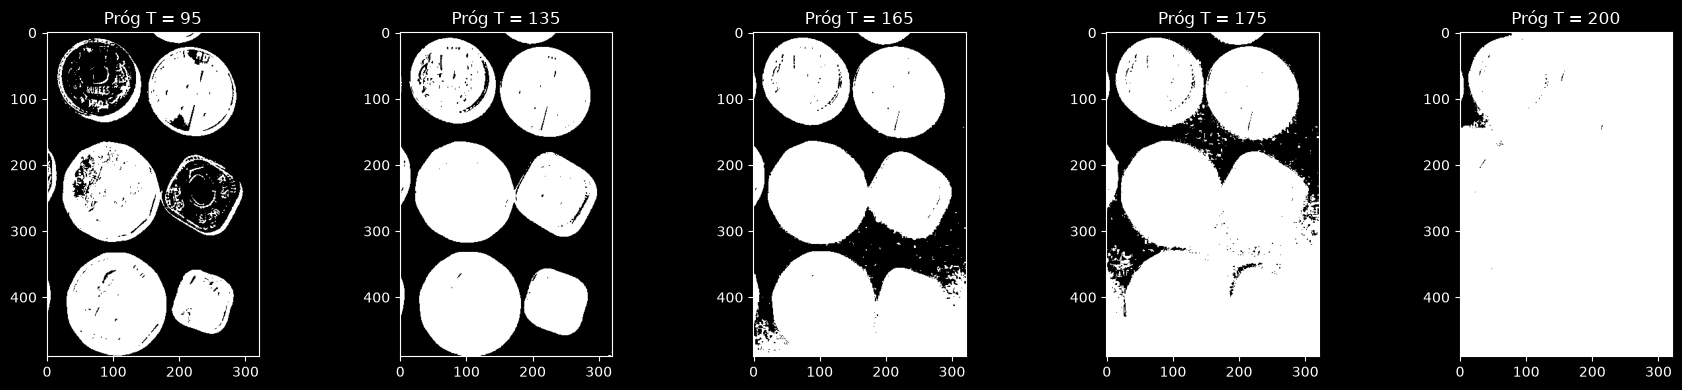

In [46]:
fig, axes = plt.subplots(1, len(progi), figsize=(18, 4))

for ax, p in zip(axes, progi):
    _, binary = cv2.threshold(gray_monety_szare, p, 255, cv2.THRESH_BINARY_INV)

    ax.imshow(binary, cmap='gray')
    ax.set_title(f'Próg T = {p}')

plt.tight_layout()
plt.show()

### Wypełnienie białych środków

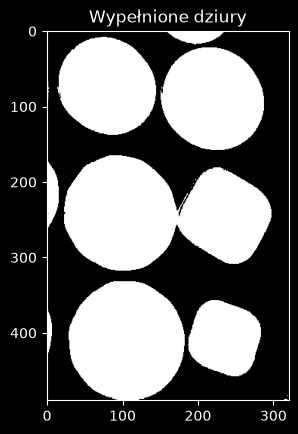

In [49]:
_, binary = cv2.threshold(gray_monety_szare, 135, 255, cv2.THRESH_BINARY_INV)
filled_binary = binary_fill_holes(binary == 255).astype(np.uint8) * 255

plt.imshow(filled_binary, cmap='gray')
plt.title('Wypełnione dziury')
plt.show()

Rozwiązanie części 1B:


In [3]:
print("Rozmiar monety_szum: " + monety_szum.shape.__str__())
gray_monety_szum = cv2.cvtColor(monety_szum, cv2.COLOR_BGR2GRAY)

Rozmiar monety_szum: (490, 321)


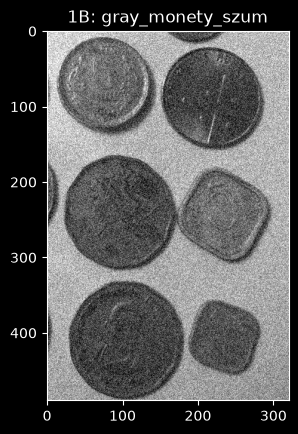

In [27]:
print("Rozmiar monety_szum: " + str(gray_monety_szum.shape))

plt.imshow(gray_monety_szum, cmap='gray')
plt.title('1B: gray_monety_szum')
plt.show()

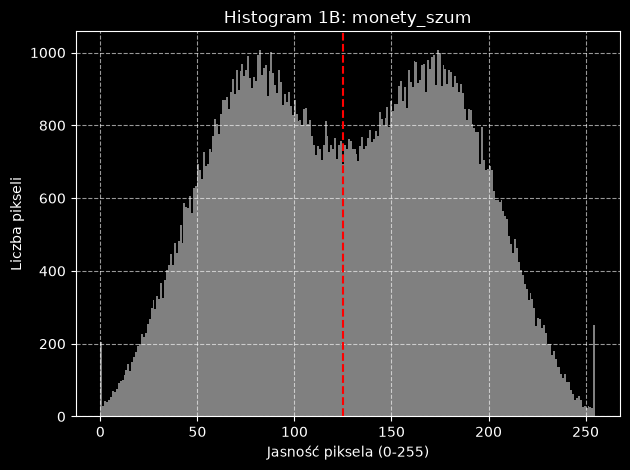

In [35]:
p_szum = 125

plt.hist(gray_monety_szum.flatten(), bins=256, color='gray', range=(0, 255))

plt.title('Histogram 1B: monety_szum')
plt.xlabel('Jasność piksela (0-255)')
plt.ylabel('Liczba pikseli')
plt.grid(True, linestyle='--', alpha=0.6)
plt.axvline(x=p_szum, color='red', linestyle='--', linewidth=1.5)

plt.tight_layout()
plt.show()

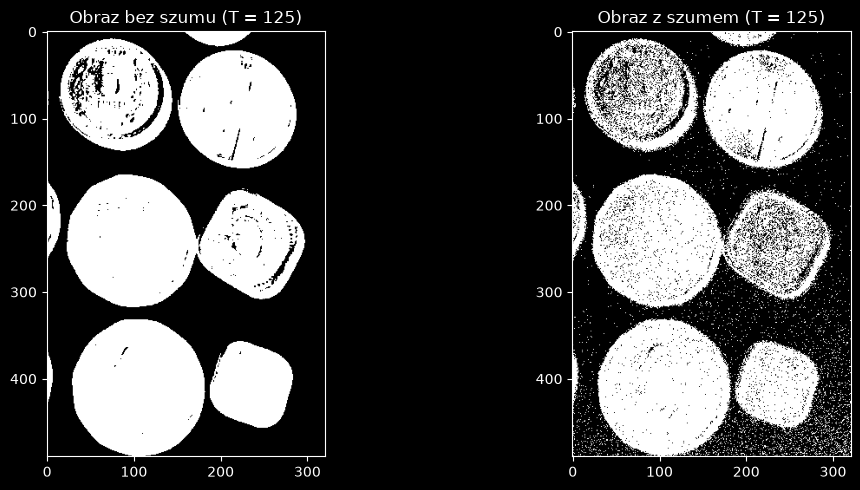

In [38]:
_, binary_szare = cv2.threshold(gray_monety_szare, p_szum, 255, cv2.THRESH_BINARY_INV)
_, binary_szum = cv2.threshold(gray_monety_szum, p_szum, 255, cv2.THRESH_BINARY_INV)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.imshow(binary_szare, cmap='gray')
ax1.set_title(f'Obraz bez szumu (T = {p_szum})')

ax2.imshow(binary_szum, cmap='gray')
ax2.set_title(f'Obraz z szumem (T = {p_szum})')

plt.tight_layout()
plt.show()

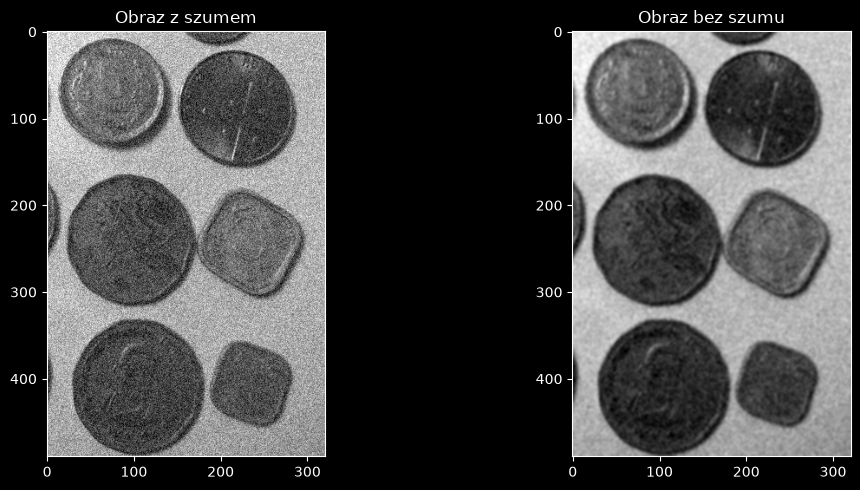

In [42]:
blurred_gray_monety_szum = cv2.GaussianBlur(gray_monety_szum, (7, 7), 0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.imshow(gray_monety_szum, cmap='gray')
ax1.set_title('Obraz z szumem')

ax2.imshow(blurred_gray_monety_szum, cmap='gray')
ax2.set_title('Obraz bez szumu')

plt.tight_layout()
plt.show()

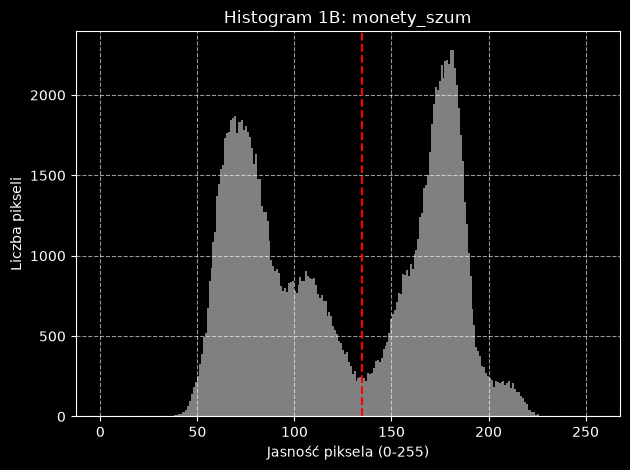

In [43]:
p_szum = 135

plt.hist(blurred_gray_monety_szum.flatten(), bins=256, color='gray', range=(0, 255))

plt.title('Histogram 1B: monety_szum')
plt.xlabel('Jasność piksela (0-255)')
plt.ylabel('Liczba pikseli')
plt.grid(True, linestyle='--', alpha=0.6)
plt.axvline(x=p_szum, color='red', linestyle='--', linewidth=1.5)

plt.tight_layout()
plt.show()

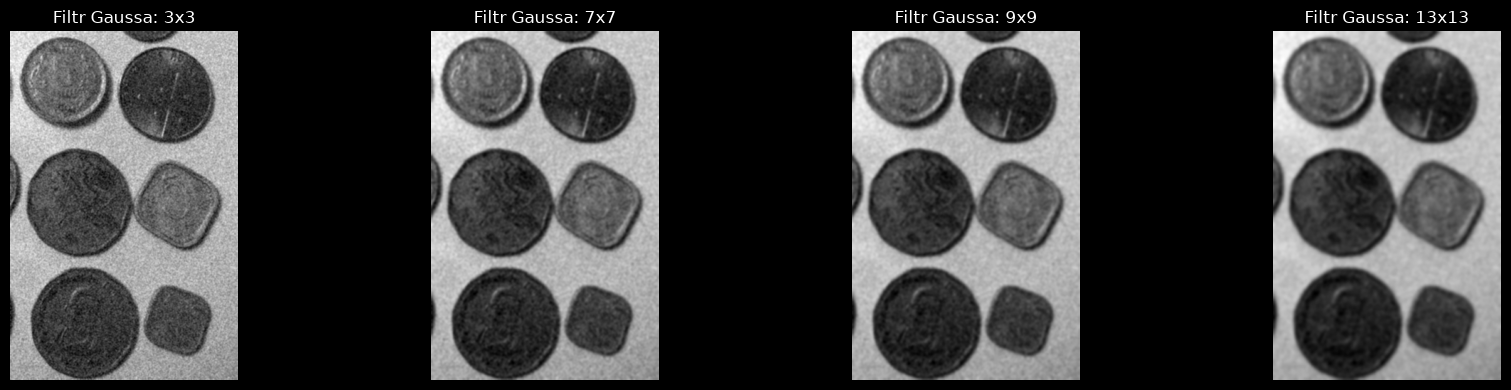

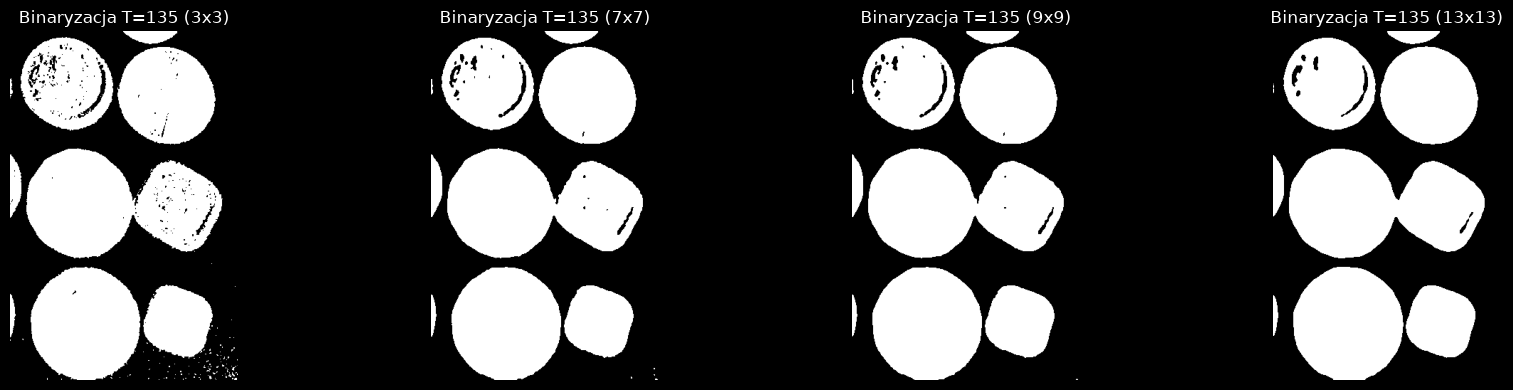

In [45]:
ksizes = [(3, 3), (7, 7), (9, 9), (13, 13)]
p = 135
fig1, axes1 = plt.subplots(1, len(ksizes), figsize=(18, 4))

blurred_images = []
for ax, ksize in zip(axes1, ksizes):
    blurred = cv2.GaussianBlur(gray_monety_szum, ksize, 0)
    blurred_images.append(blurred)

    ax.imshow(blurred, cmap='gray')
    ax.set_title(f'Filtr Gaussa: {ksize[0]}x{ksize[1]}')
    ax.axis('off')

plt.tight_layout()
plt.show()

fig2, axes2 = plt.subplots(1, len(ksizes), figsize=(18, 4))

for ax, blurred, ksize in zip(axes2, blurred_images, ksizes):
    _, binary = cv2.threshold(blurred, p, 255, cv2.THRESH_BINARY_INV)

    ax.imshow(binary, cmap='gray')
    ax.set_title(f'Binaryzacja T={p} ({ksize[0]}x{ksize[1]})')
    ax.axis('off')

plt.tight_layout()
plt.show()

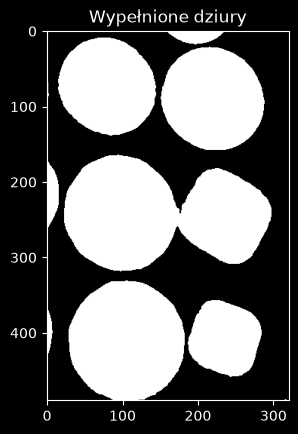

In [52]:
blurred = cv2.GaussianBlur(gray_monety_szum, (9, 9), 0)
_, binary = cv2.threshold(blurred, 135, 255, cv2.THRESH_BINARY_INV)
filled_binary = binary_fill_holes(binary == 255).astype(np.uint8) * 255

plt.imshow(filled_binary, cmap='gray')
plt.title('Wypełnione dziury')
plt.show()

##### Zad. 2: Monety kolorowe

Na podobnej zasadzie dokonaj binaryzacji poniższego obrazu kolorowego.  
Skorzystaj z modelu barw HSV. Uzasadnij dobór kanału oraz progu binaryzacji.

'(591, 1275, 3)'

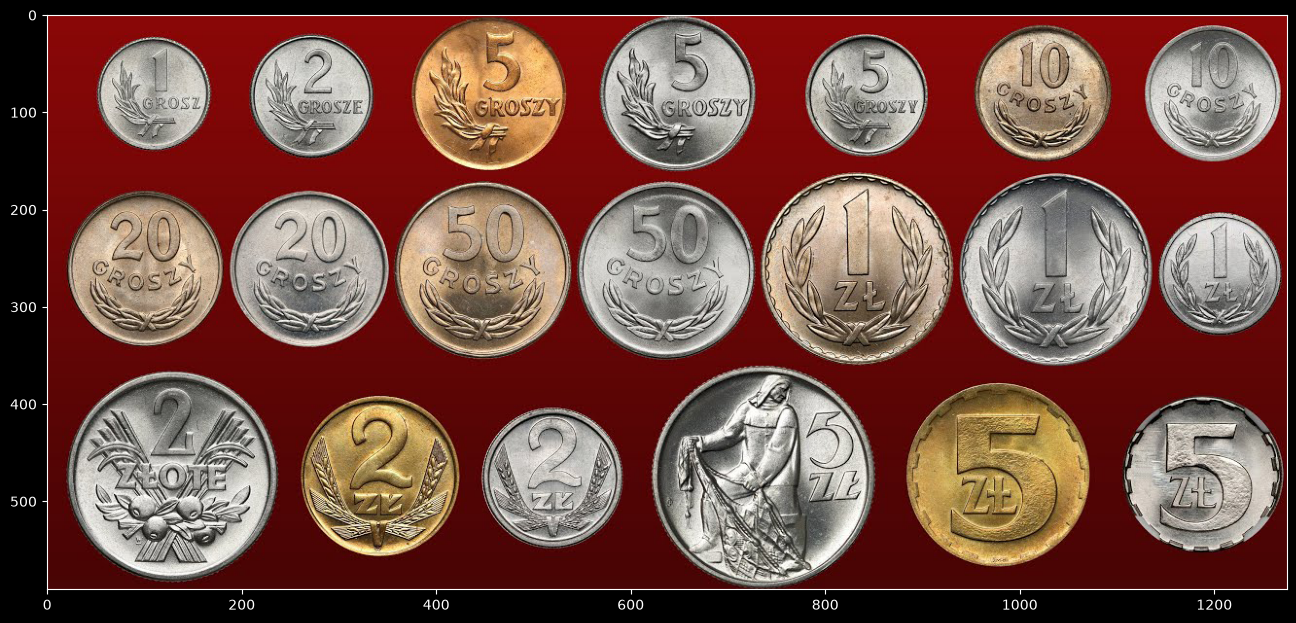

In [55]:
monety_kolor = cv2.imread('Monety_kolor.bmp')
plt.subplots(1,1,figsize=(16,8))[1].imshow(monety_kolor[..., ::-1])
str(monety_kolor.shape)

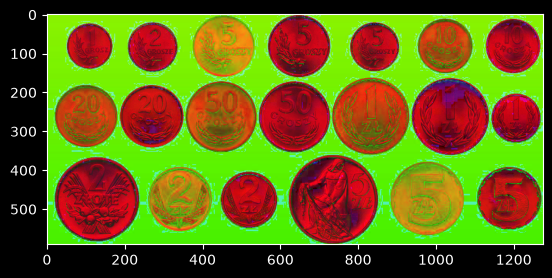

In [59]:
monety_kolor_hsv = cv2.cvtColor(monety_kolor, cv2.COLOR_BGR2HSV)
plt.imshow(monety_kolor_hsv[..., ::-1])

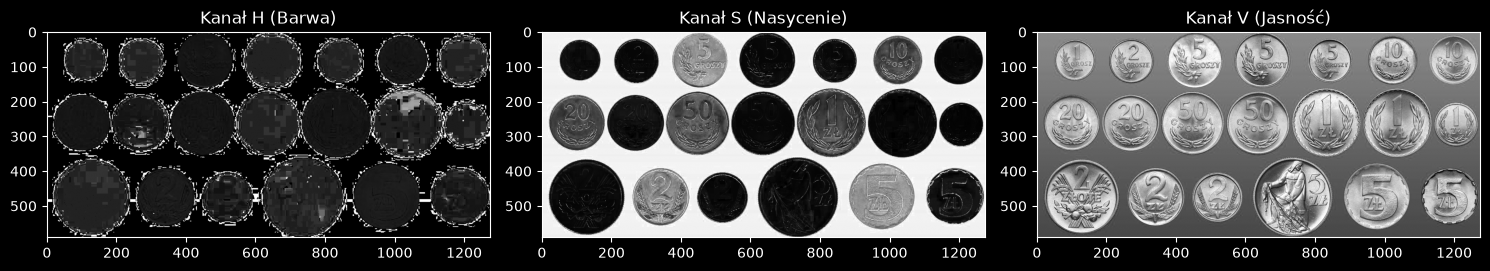

In [60]:
h, s, v = cv2.split(monety_kolor_hsv)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(h, cmap='gray')
axes[0].set_title('Kanał H (Barwa)')

axes[1].imshow(s, cmap='gray')
axes[1].set_title('Kanał S (Nasycenie)')

axes[2].imshow(v, cmap='gray')
axes[2].set_title('Kanał V (Jasność)')

plt.tight_layout()
plt.show()

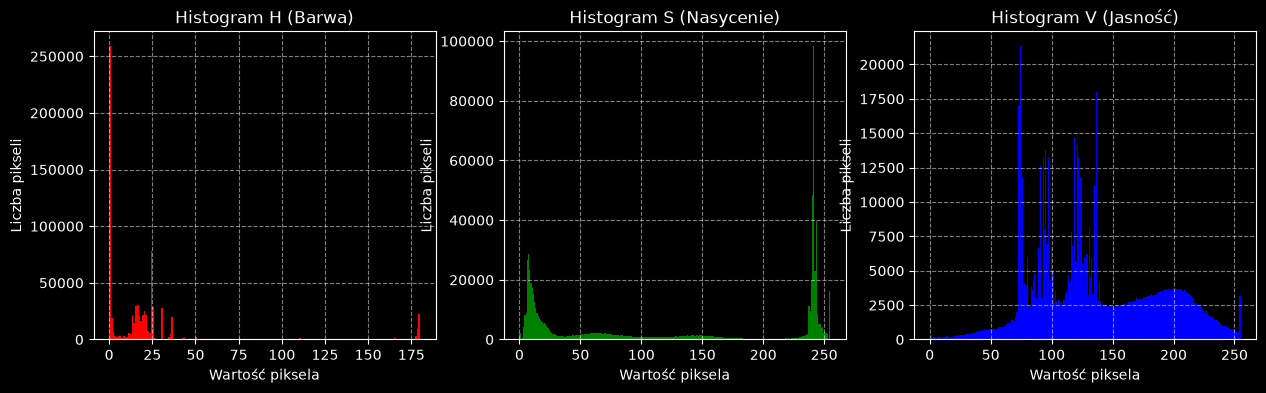

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Kanał H ma w OpenCV zakres 0-179
axes[0].hist(h.flatten(), bins=180, color='red', range=(0, 180))
axes[0].set_title('Histogram H (Barwa)')

# Kanały S i V mają zakres 0-255
axes[1].hist(s.flatten(), bins=256, color='green', range=(0, 255))
axes[1].set_title('Histogram S (Nasycenie)')

axes[2].hist(v.flatten(), bins=256, color='blue', range=(0, 255))
axes[2].set_title('Histogram V (Jasność)')

for ax in axes:
    ax.set_xlabel('Wartość piksela')
    ax.set_ylabel('Liczba pikseli')
    ax.grid(True, linestyle='--', alpha=0.5)

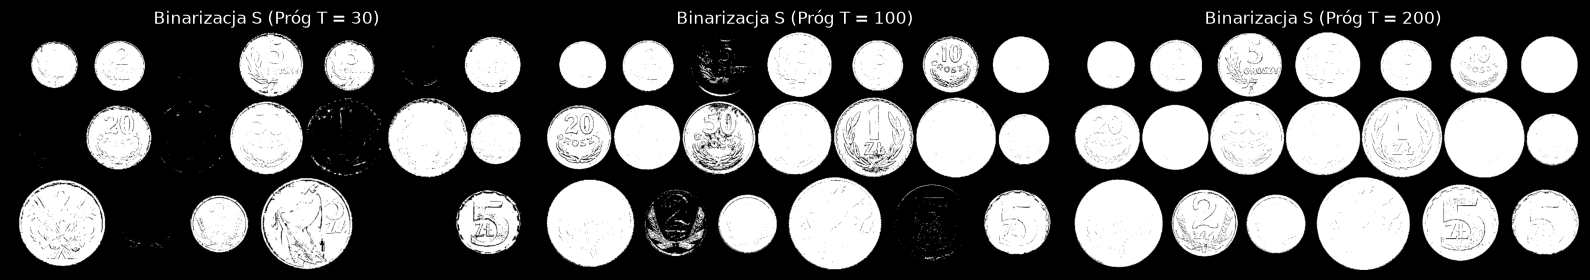

In [63]:
s_channel = monety_kolor_hsv[:, :, 1]

progi = [30, 100, 200]
fig, axes = plt.subplots(1, len(progi), figsize=(16, 5))

for ax, p in zip(axes, progi):
    _, binary = cv2.threshold(s_channel, p, 255, cv2.THRESH_BINARY_INV)

    ax.imshow(binary, cmap='gray')
    ax.set_title(f'Binarizacja S (Próg T = {p})')
    ax.axis('off')

plt.tight_layout()
plt.show()

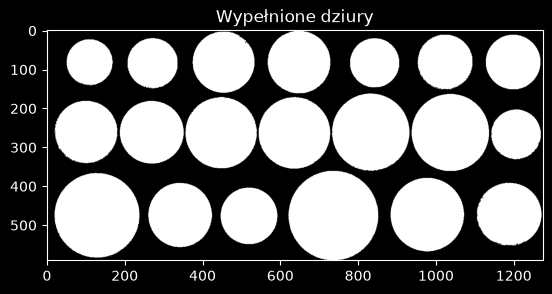

In [64]:
_, binary = cv2.threshold(s_channel, 200, 255, cv2.THRESH_BINARY_INV)
filled_binary = binary_fill_holes(binary == 255).astype(np.uint8) * 255

plt.imshow(filled_binary, cmap='gray')
plt.title('Wypełnione dziury')
plt.show()

Przetestuj opracowany powyżej algorytm na poniższym obrazie z wyraźnym zaszumieniem. Co się zmienia i dlaczego? Uzupełnij potok przetwarzania o odszumianie.

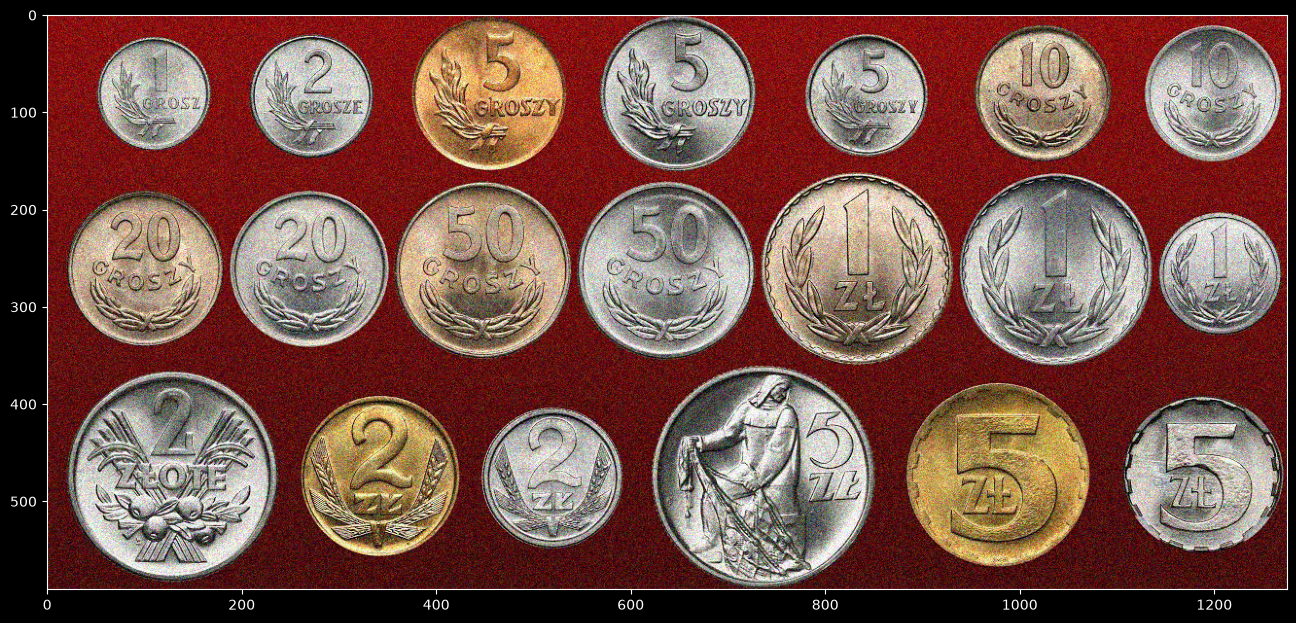

In [5]:
monety_kolor_szum = cv2.imread('Monety_kolor_szum.bmp')
plt.subplots(1,1,figsize=(16,8))[1].imshow(monety_kolor_szum[..., ::-1]);

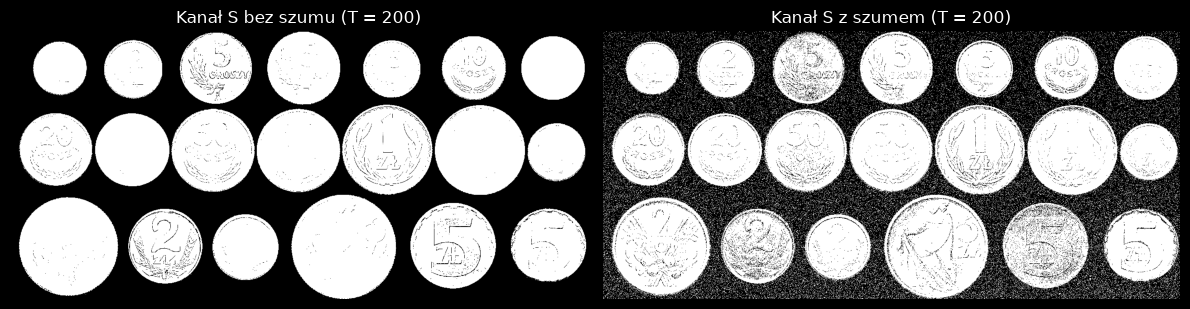

In [65]:
p_s = 200

monety_kolor_szum_hsv = cv2.cvtColor(monety_kolor_szum, cv2.COLOR_BGR2HSV)

s_clean = monety_kolor_hsv[:, :, 1]
s_szum = monety_kolor_szum_hsv[:, :, 1]

_, binary_clean = cv2.threshold(s_clean, p_s, 255, cv2.THRESH_BINARY_INV)
_, binary_szum = cv2.threshold(s_szum, p_s, 255, cv2.THRESH_BINARY_INV)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.imshow(binary_clean, cmap='gray')
ax1.set_title(f'Kanał S bez szumu (T = {p_s})')
ax1.axis('off')

ax2.imshow(binary_szum, cmap='gray')
ax2.set_title(f'Kanał S z szumem (T = {p_s})')
ax2.axis('off')

plt.tight_layout()
plt.show()

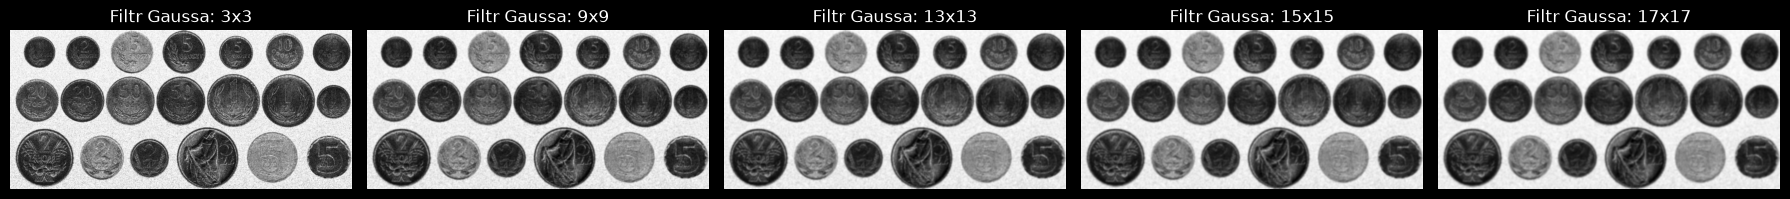

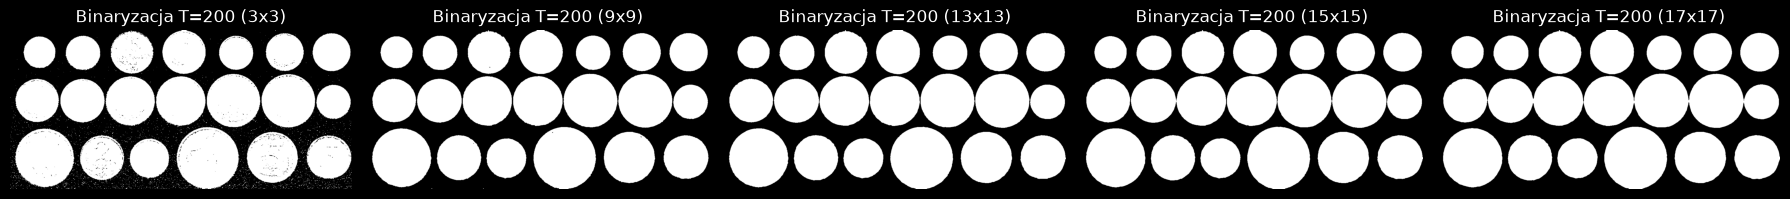

In [71]:
ksizes = [(3, 3), (9, 9), (13, 13), (15, 15), (17, 17)]
p = 200
fig1, axes1 = plt.subplots(1, len(ksizes), figsize=(18, 4))

blurred_images = []
for ax, ksize in zip(axes1, ksizes):
    blurred = cv2.GaussianBlur(s_szum, ksize, 0)
    blurred_images.append(blurred)

    ax.imshow(blurred, cmap='gray')
    ax.set_title(f'Filtr Gaussa: {ksize[0]}x{ksize[1]}')
    ax.axis('off')

plt.tight_layout()
plt.show()

fig2, axes2 = plt.subplots(1, len(ksizes), figsize=(18, 4))

for ax, blurred, ksize in zip(axes2, blurred_images, ksizes):
    _, binary = cv2.threshold(blurred, p, 255, cv2.THRESH_BINARY_INV)

    ax.imshow(binary, cmap='gray')
    ax.set_title(f'Binaryzacja T={p} ({ksize[0]}x{ksize[1]})')
    ax.axis('off')

plt.tight_layout()
plt.show()

##### Zad. 3: Tekst

W tym przypadku należy wyodrębnić litery od bardzo nierównomiernie oświetlonego tła. Skorzystaj z binaryzacji metodą Otsu. Zastosuj binaryzację w sposób lokalny (oknem przesuwnym). Jaki wpływ ma rozmiar okna na jakość binaryzacji? Jak przesuwać okno?

_(Pełna punktacja za zadanie wymaga własnoręcznej implementacji okna przesuwnego - samo Otsu możesz wziąć z OpenCV. Użycie zamiast tego_ `cv2.adaptiveThreshold` _liczone będzie jako pół zadania, ale jedynie po demonstracji zrozumienia tej metody.)_

In [67]:
tekst = cv2.imread('Tekst1.bmp')
Image.fromarray(cv2.cvtColor(tekst, cv2.COLOR_BGR2GRAY))

error: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'


Rozwiązanie: